In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('data/Spotify_Dataset_V3.csv', delimiter=';')


Text(0.5, 1.0, 'Histogram of Loudness (default)')

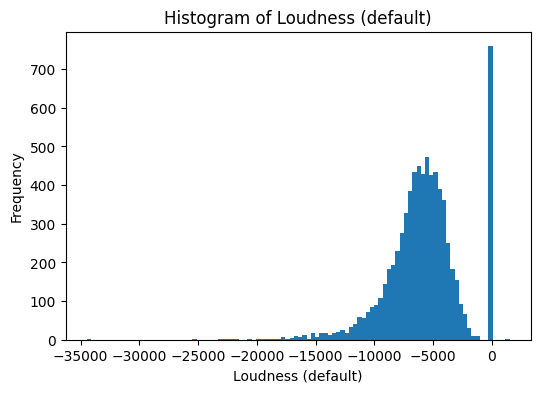

In [84]:
# Original loudness

def scale_loudness(x):
    # DB values already correct
    if -22 <= x < 0:
        return x
    # Rescale majority of values
    elif x <-22:
        return x / 600
    # rescale singuler large value
    elif x > 1:
        return -x/1000
    # rescale 2x values
    elif 0 < x <=1:
        return -x*10
    else:
        return np.nan
    
loudness_df = df[['Title', 'Loudness', 'Artists']].copy()  
# remove duplicate rows (i.e. get list of unique titles and their loudness)
loudness_df = loudness_df.drop_duplicates(subset=['Title'])

# Create a singular plot
fig, axs = plt.subplots(figsize=(6, 4))

# Original loudness histogram
loudness_df["Loudness"].plot(kind="hist", logy=False, bins=100, ax=axs)
axs.set_xlabel("Loudness (default)")
axs.set_title("Histogram of Loudness (default)")

In [85]:
# Extract rows with loudness values around 1
spike_rows = loudness_df[(loudness_df['Loudness'] >= -2) & (loudness_df['Loudness'] <= 1)]
#print(spike_rows[['Title', 'Artists', 'Loudness']])

# finding outliers

Q1 = loudness_df['Loudness'].quantile(0.25)
Q3 = loudness_df['Loudness'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = loudness_df[(loudness_df['Loudness'] < lower_bound) | (loudness_df['Loudness'] > upper_bound)]

print(f"Found {len(outliers)} outliers")
print(outliers[['Title', 'Artists', 'Loudness']])
# print unique outlier titles
unique_outlier_titles = outliers['Title'].unique()
print("Unique outlier titles:")
for title in unique_outlier_titles:
    print(f"- {title}")
# print number of unique outlier titles
print(f"Total unique outlier titles: {len(unique_outlier_titles)}")

Found 222 outliers
                                                    Title  \
255                                    Stargirl Interlude   
269                                         METAMORPHOSIS   
1065               Snow On The Beach (feat. Lana Del Rey)   
4019                                       hotline (edit)   
10366                                             Revenge   
...                                                   ...   
637113  Mia & Sebastian's Theme - From "La La Land" So...   
640332                                        Skinny Love   
645291                                          Neighbors   
646984                      You're Gon Live Forever in Me   
648774                                            Test Me   

                           Artists  Loudness  
255       The Weeknd, Lana Del Rey  -12638.0  
269                     INTERWORLD  -12727.0  
1065    Taylor Swift, Lana Del Rey  -13481.0  
4019                 Billie Eilish  -16027.0  
10366        

Range [-0.5, 0.0): 3 songs
------------------------------------------------------------
Range [-1.0, -0.5): 8 songs
------------------------------------------------------------
Range [-1.5, -1.0): 3 songs
------------------------------------------------------------
Range [-2.0, -1.5): 5 songs
------------------------------------------------------------
Range [-2.5, -2.0): 9 songs
------------------------------------------------------------
Range [-3.0, -2.5): 16 songs
------------------------------------------------------------
Range [-3.5, -3.0): 36 songs
------------------------------------------------------------
Range [-4.0, -3.5): 36 songs
------------------------------------------------------------
Range [-4.5, -4.0): 44 songs
------------------------------------------------------------
Range [-5.0, -4.5): 74 songs
------------------------------------------------------------
Number of songs with Loudness between -2.5 and 0.0 dB: 28


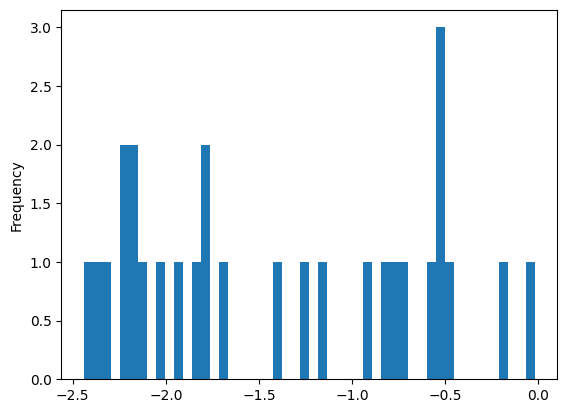

                                                    Title  \
506895                                      The Explation   
347866                                           JACKBOYS   
414500                                 listen before i go   
383179                             Litanie contre la Peur   
44564                                  Carol of the Bells   
506566                                            Orlando   
506452                            Dead Inside (Interlude)   
423121                                            goodbye   
186666                                           Big Star   
458948                                       Introduction   
635006  I See Fire - From "The Hobbit - The Desolation...   
250506  It's Not Christmas 'Til You Come Home - Record...   
156643                                      Eminem Speaks   
250449                     Christmas Time Is Here - Vocal   
557415                         O Little Town of Bethlehem   

                       

,Title,Artists,Loudness
14,Classy 101,"Feid, Young Miko",-4.79
15,Classy 101,"Feid, Young Miko",-4.79
25,"Angel Pt. 1 (feat. Jimin of BTS, JVKE & Muni L...","Kodak Black, NLE Choppa, Jimin, JVKE, Muni Long",-4.25
26,"Angel Pt. 1 (feat. Jimin of BTS, JVKE & Muni L...","Kodak Black, NLE Choppa, Jimin, JVKE, Muni Long",-4.25
27,"Angel Pt. 1 (feat. Jimin of BTS, JVKE & Muni L...","Kodak Black, NLE Choppa, Jimin, JVKE, Muni Long",-4.25


In [91]:
# find range of songs in half db intervals
bins = [(s, s + 0.5) for s in np.arange(-5.0, 0.0, 0.5)]
for low, high in reversed(bins):
    clippedDF = loudness_df[(loudness_df['Loudness'] >= low) & (loudness_df['Loudness'] < high)]
    print(f"Range [{low:.1f}, {high:.1f}): {len(clippedDF)} songs")
    print('-' * 60)

clippedDF = loudness_df[(loudness_df['Loudness'] > -2.5) & (loudness_df['Loudness'] < 0.0)]
# print number of songs in clippedDF
print(f"Number of songs with Loudness between -2.5 and 0.0 dB: {len(clippedDF)}")
clippedDF["Loudness"].plot(kind="hist", bins=50)
# show plot
plt.show()

# smallest Loudness_dB values

smallest = loudness_df.sort_values('Loudness_dB', ascending=True).head(15)
print(smallest[['Title','Artists', 'Loudness', 'Loudness_dB']])

# check number of rows with original Loudness in [-22, 0)
original_between = df[(df['Loudness'] >= -22) & (df['Loudness'] < 0)].copy()
print(f"Found {len(original_between)} rows with original Loudness in [-30, 0):")
original_between[['Title', 'Artists', 'Loudness']].head(5)

In [87]:
# search for outliers
# get unique song titles for loudness > 0
# get unique titles with Loudness > 0 and their sorted unique loudness values
title_loudness = (loudness_df[loudness_df['Loudness'] > 0]
                  .groupby('Title')['Loudness']
                  .apply(lambda s: sorted(s.unique()))
                  .sort_index())

unique_titles = list(title_loudness.index)
print(f"Found {len(unique_titles)} unique song titles with Loudness > 0:")
for t, vals in title_loudness.items():
    print(f"- {t}: {vals}")

# find nan values within loudness
nan_loudness = loudness_df[loudness_df['Loudness'].isna()]
print(f"Found {len(nan_loudness)} rows with NaN Loudness values")

Found 3 unique song titles with Loudness > 0:
- Na Raba Toma Tapão: [np.float64(1509.0)]
- Puta Mexica: [np.float64(0.963)]
- Welcome to the Party (with French Monta & Lil Pump, feat. Zhavia Ward) - from Deadpool 2: [np.float64(0.175)]
Found 0 rows with NaN Loudness values


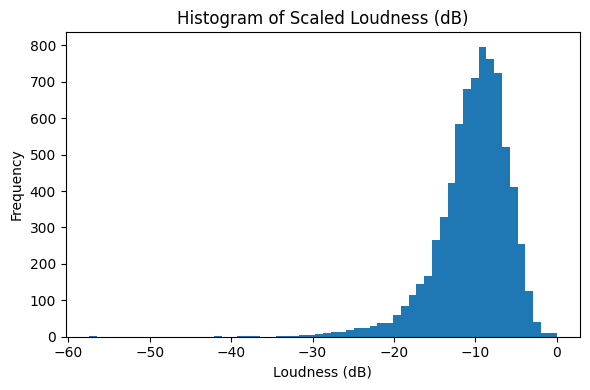

In [ ]:
fig, axs = plt.subplots(figsize=(6, 4))

loudness_df["Loudness_dB"] = loudness_df['Loudness'].apply(scale_loudness)

# Scaled loudness histogram
loudness_df["Loudness_dB"].plot(kind="hist", logy=False, bins=60, ax=axs, )
axs.set_xlabel("Loudness (dB)")
axs.set_title("Histogram of Scaled Loudness (dB)")
fig.tight_layout()

plt.show()


